# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from pathlib import Path
import joblib
import json


from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras import callbacks

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

import warnings
warnings.filterwarnings("ignore")

# Load Dataset

In [2]:
PROJECT_ROOT = Path(".").resolve().parent 

DATA_DIR   = PROJECT_ROOT / "Data"  
ASSET_DIR  = PROJECT_ROOT / "Assets" 
MODEL_DIR  = PROJECT_ROOT / "Models" 

df1 = pd.read_csv(DATA_DIR / "diabetes_012_health_indicators_BRFSS2015_BRFSS2021.csv")

# Split the raw dataset first

All three ANN strategies use the same stratified train/validation/test split from `df1`. The balanced strategy is made by downsampling only `df1`'s training partition. SMOTE is likewise applied only to `df1`'s training partition. The validation and test partitions remain untouched and retain the original class distribution.


In [3]:
df1.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income',
       'Year', 'Health_Status', 'Health_Status_Label'],
      dtype='object')

In [4]:
df1.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Year,Health_Status,Health_Status_Label
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,18.0,15.0,1.0,0.0,9.0,4.0,3.0,2015,0,Healthy
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,7.0,6.0,1.0,2015,0,Healthy
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,30.0,30.0,1.0,0.0,9.0,4.0,8.0,2015,0,Healthy
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,11.0,3.0,6.0,2015,0,Healthy
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,3.0,0.0,0.0,0.0,11.0,5.0,4.0,2015,0,Healthy


In [5]:
df1.shape

(453331, 25)

## ***DF1***

In [6]:
x_df1 = df1[['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income'
       ]]

y_df1 = df1["Health_Status"]

In [7]:
xtrain_val_df1, xtest_df1, ytrain_val_df1, ytest_df1 = train_test_split(
    x_df1, y_df1, test_size=0.20, random_state=42, shuffle=True, stratify=y_df1
)

xtrain_df1, xval_df1, ytrain_df1, yval_df1 = train_test_split(
    xtrain_val_df1, ytrain_val_df1, test_size=0.20, random_state=42, shuffle=True, stratify=ytrain_val_df1
)

print(f"Train shape: {xtrain_df1.shape}   Validation shape: {xval_df1.shape}   Test shape: {xtest_df1.shape}")

Train shape: (290131, 21)   Validation shape: (72533, 21)   Test shape: (90667, 21)


## Balanced dataset reference (`df2`) and leakage-safe model 2 setup


In [8]:
train_for_downsampling = xtrain_df1.copy()
train_for_downsampling["Health_Status"] = ytrain_df1

class_counts = train_for_downsampling["Health_Status"].value_counts()
if len(class_counts) != 2:
    raise ValueError(f"Expected a binary target with 2 classes, got: {class_counts.to_dict()}")

majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()

majority_rows = train_for_downsampling[
    train_for_downsampling["Health_Status"] == majority_class
].sample(n=int(class_counts.loc[minority_class]), random_state=42)
minority_rows = train_for_downsampling[
    train_for_downsampling["Health_Status"] == minority_class
]

balanced_train_df = pd.concat([majority_rows, minority_rows], axis=0).sample(
    frac=1, random_state=42
)

xtrain_df2 = balanced_train_df[x_df1.columns].copy()
ytrain_df2 = balanced_train_df["Health_Status"].copy()

xval_df2, yval_df2 = xval_df1, yval_df1
xtest_df2, ytest_df2 = xtest_df1, ytest_df1

print("Balanced Model 2 training shape:", xtrain_df2.shape)
print("Balanced Model 2 training class distribution:\n", ytrain_df2.value_counts().sort_index())
print("Shared validation shape:", xval_df2.shape)
print("Shared test shape:", xtest_df2.shape)
print("\nNote: full df2 remains available as x_df2/y_df2 for inspection; model 2 uses only the leakage-safe balanced training subset above.")

Balanced Model 2 training shape: (100780, 21)
Balanced Model 2 training class distribution:
 Health_Status
0    50390
1    50390
Name: count, dtype: int64
Shared validation shape: (72533, 21)
Shared test shape: (90667, 21)

Note: full df2 remains available as x_df2/y_df2 for inspection; model 2 uses only the leakage-safe balanced training subset above.


# Scale the features

In [9]:
binary_cols = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]

numerical_and_ordinal_cols = [
    'BMI', 'MentHlth', 'PhysHlth', 'GenHlth', 'Age', 'Education', 'Income'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), numerical_and_ordinal_cols)
    ],
    remainder='passthrough' 
)

xtrain_scaled_df1 = preprocessor.fit_transform(xtrain_df1)
xval_scaled_df1 = preprocessor.transform(xval_df1)
xtest_scaled_df1 = preprocessor.transform(xtest_df1)

print(f"Train shape: {xtrain_scaled_df1.shape}   Validation shape: {xval_scaled_df1.shape}   Test shape: {xtest_scaled_df1.shape}")

Train shape: (290131, 21)   Validation shape: (72533, 21)   Test shape: (90667, 21)


In [10]:
xtrain_df1.head()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
55295,1.0,1.0,1.0,31.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,12.0,4.0,7.0
333151,0.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,1.0,3.0,0.0,1.0,8.0,6.0,6.0
87744,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,3.0,0.0,7.0,1.0,1.0,6.0,4.0,8.0
343401,0.0,1.0,1.0,28.0,1.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,10.0,5.0,7.0
199699,0.0,0.0,1.0,25.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,2.0,20.0,0.0,0.0,0.0,4.0,5.0,8.0


In [11]:
pd.DataFrame(xtrain_scaled_df1).head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,0.307377,-0.484373,-0.494387,0.414317,1.264385,-1.066150,0.281340,1.0,1.0,1.0,...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
1,-0.137214,-0.357895,-0.152234,0.414317,0.004774,0.983244,-0.155885,0.0,1.0,1.0,...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
2,-0.137214,-0.484373,0.303970,0.414317,-0.625032,-1.066150,0.718565,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
3,-0.137214,-0.484373,-0.494387,0.414317,0.634579,-0.041453,0.281340,0.0,1.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
4,-0.581806,2.045198,-0.494387,-0.539868,-1.254838,-0.041453,0.718565,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [12]:
xtrain_scaled_df2 = preprocessor.transform(xtrain_df2)
xval_scaled_df2 = xval_scaled_df1
xtest_scaled_df2 = xtest_scaled_df1

print(f"Balanced training shape: {xtrain_scaled_df2.shape}   Validation shape: {xval_scaled_df2.shape}   Test shape: {xtest_scaled_df2.shape}")

Balanced training shape: (100780, 21)   Validation shape: (72533, 21)   Test shape: (90667, 21)


In [13]:
pd.DataFrame(xtrain_scaled_df2).head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,-1.026397,-0.104938,-0.494387,-0.539868,0.949482,-1.066150,-0.155885,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1,-0.433609,-0.484373,-0.494387,-0.539868,0.949482,-0.041453,-0.155885,0.0,1.0,1.0,...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
2,1.344756,3.309983,0.075868,1.368502,-0.625032,-0.041453,-0.593109,0.0,1.0,1.0,...,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
3,0.603771,0.148019,0.646124,1.368502,-1.884644,0.983244,-1.904783,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-0.285412,-0.484373,-0.494387,-0.539868,-2.199546,-0.041453,-1.467558,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


# SMOTE (Synthetic Minority Over-sampling Technique)

In [14]:
smote = SMOTE(random_state=42)

xtrain_resampled_df1, ytrain_resampled_df1 = smote.fit_resample(xtrain_scaled_df1, ytrain_df1)

print("Before SMOTE - Training class distribution:\n", pd.Series(ytrain_df1).value_counts())
print("\nAfter SMOTE - Training class distribution:\n", pd.Series(ytrain_resampled_df1).value_counts())
print(f"\nResampled training shape: {xtrain_resampled_df1.shape}")

Before SMOTE - Training class distribution:
 Health_Status
0    239741
1     50390
Name: count, dtype: int64

After SMOTE - Training class distribution:
 Health_Status
0    239741
1    239741
Name: count, dtype: int64

Resampled training shape: (479482, 21)


# Build the ANN


## for raw df1

In [15]:
model1 = keras.Sequential([
    keras.Input(shape=(xtrain_scaled_df1.shape[1],)),
    
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    
    # layers.Dense(3, activation="softmax")
    layers.Dense(1, activation="sigmoid")
])

model1.summary() 

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               2816      
                                                                 
 batch_normalization (BatchN  (None, 128)              512       
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 batch_normalization_1 (Batc  (None, 64)               256       
 hNormalization)                                                 
                                                                 
 dropout_1 (Dropout)         (None, 64)                0

## for balanced dataset df2

In [16]:
model2 = keras.Sequential([
    keras.Input(shape=(xtrain_scaled_df2.shape[1],)),
    
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    
    # layers.Dense(3, activation="softmax")
    layers.Dense(1, activation="sigmoid")
])

model2.summary() 

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 128)               2816      
                                                                 
 batch_normalization_2 (Batc  (None, 128)              512       
 hNormalization)                                                 
                                                                 
 dropout_3 (Dropout)         (None, 128)               0         
                                                                 
 dense_5 (Dense)             (None, 64)                8256      
                                                                 
 batch_normalization_3 (Batc  (None, 64)               256       
 hNormalization)                                                 
                                                                 
 dropout_4 (Dropout)         (None, 64)               

## after using smote

In [17]:
model3 = keras.Sequential([
    keras.Input(shape=(xtrain_resampled_df1.shape[1],)),
    
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    
    # layers.Dense(3, activation="softmax")
    layers.Dense(1, activation="sigmoid")
])

model3.summary() 

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_8 (Dense)             (None, 128)               2816      
                                                                 
 batch_normalization_4 (Batc  (None, 128)              512       
 hNormalization)                                                 
                                                                 
 dropout_6 (Dropout)         (None, 128)               0         
                                                                 
 dense_9 (Dense)             (None, 64)                8256      
                                                                 
 batch_normalization_5 (Batc  (None, 64)               256       
 hNormalization)                                                 
                                                                 
 dropout_7 (Dropout)         (None, 64)               

# Compile the model


In [18]:
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    # loss="sparse_categorical_crossentropy",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [19]:
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    # loss="sparse_categorical_crossentropy",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [20]:
model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    # loss="sparse_categorical_crossentropy",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train the model

In [21]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [22]:
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(ytrain_df1),
    y=ytrain_df1
)

class_weights = dict(enumerate(class_weights_array))
print("Computed Class Weights:", class_weights)

Computed Class Weights: {0: 0.6050925790749183, 1: 2.8788549315340344}


# raw dataset

In [23]:
history1 = model1.fit(
    xtrain_scaled_df1,
    ytrain_df1,
    class_weight=class_weights,
    batch_size=256,
    epochs=200,
    validation_data=(xval_scaled_df1, yval_df1),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
1134/1134 [==============================] - 16s 13ms/step - loss: 0.5669 - accuracy: 0.6753 - val_loss: 0.5405 - val_accuracy: 0.6939
Epoch 2/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5427 - accuracy: 0.6934 - val_loss: 0.5350 - val_accuracy: 0.6934
Epoch 3/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5403 - accuracy: 0.6955 - val_loss: 0.5263 - val_accuracy: 0.7019
Epoch 4/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5393 - accuracy: 0.6953 - val_loss: 0.5307 - val_accuracy: 0.7059
Epoch 5/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5384 - accuracy: 0.6963 - val_loss: 0.5286 - val_accuracy: 0.7020
Epoch 6/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5376 - accuracy: 0.6992 - val_loss: 0.5532 - val_accuracy: 0.6871
Epoch 7/200
1134/1134 [==============================] - 15s 13ms/step - loss: 0.5373 - accuracy: 0.6995 - val_loss: 0

# Balanced training strategy: random downsampling to 50:50 within df1_train only


In [24]:
history2 = model2.fit(
    xtrain_scaled_df2,
    ytrain_df2,
    batch_size=256,
    epochs=200,
    validation_data=(xval_scaled_df2, yval_df2),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
394/394 [==============================] - 7s 16ms/step - loss: 0.5863 - accuracy: 0.6981 - val_loss: 0.5263 - val_accuracy: 0.6960
Epoch 2/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5501 - accuracy: 0.7234 - val_loss: 0.5198 - val_accuracy: 0.7071
Epoch 3/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5457 - accuracy: 0.7266 - val_loss: 0.5348 - val_accuracy: 0.6952
Epoch 4/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5419 - accuracy: 0.7296 - val_loss: 0.5280 - val_accuracy: 0.6954
Epoch 5/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5410 - accuracy: 0.7294 - val_loss: 0.5300 - val_accuracy: 0.7072
Epoch 6/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5399 - accuracy: 0.7306 - val_loss: 0.5206 - val_accuracy: 0.7062
Epoch 7/200
394/394 [==============================] - 6s 15ms/step - loss: 0.5388 - accuracy: 0.7306 - val_loss: 0.5318 - val_accuracy:

# using SMOTE

In [25]:
history3 = model3.fit(
    xtrain_resampled_df1,
    ytrain_resampled_df1,
    batch_size=256,
    epochs=200,
    validation_data=(xval_scaled_df1, yval_df1),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
1873/1873 [==============================] - 24s 12ms/step - loss: 0.5408 - accuracy: 0.7302 - val_loss: 0.5592 - val_accuracy: 0.6918
Epoch 2/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5236 - accuracy: 0.7411 - val_loss: 0.5136 - val_accuracy: 0.7179
Epoch 3/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5202 - accuracy: 0.7435 - val_loss: 0.5281 - val_accuracy: 0.7092
Epoch 4/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5177 - accuracy: 0.7445 - val_loss: 0.5300 - val_accuracy: 0.7098
Epoch 5/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5150 - accuracy: 0.7464 - val_loss: 0.5185 - val_accuracy: 0.7139
Epoch 6/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5123 - accuracy: 0.7474 - val_loss: 0.5256 - val_accuracy: 0.7092
Epoch 7/200
1873/1873 [==============================] - 23s 12ms/step - loss: 0.5091 - accuracy: 0.7503 - val_loss: 0

# Evaluate and predict


# raw

              precision    recall  f1-score   support

     Healthy       0.93      0.69      0.79     74920
     At Risk       0.34      0.77      0.47     15747

    accuracy                           0.70     90667
   macro avg       0.64      0.73      0.63     90667
weighted avg       0.83      0.70      0.74     90667

[[51625 23295]
 [ 3648 12099]]


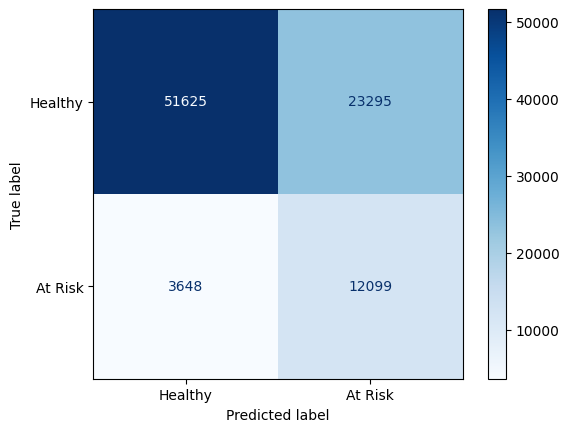

In [26]:
y_prob1 = model1.predict(xtest_scaled_df1, verbose=0).ravel()
y_pred1 = (y_prob1 >= 0.5).astype(int)

print(classification_report(
    ytest_df1,
    y_pred1,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm = confusion_matrix(ytest_df1, y_pred1)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.savefig(ASSET_DIR / "confusion_matrix_model1_raw.png", dpi=300, bbox_inches="tight")
plt.show()

# balanced

              precision    recall  f1-score   support

     Healthy       0.93      0.70      0.80     74920
     At Risk       0.34      0.76      0.47     15747

    accuracy                           0.71     90667
   macro avg       0.64      0.73      0.64     90667
weighted avg       0.83      0.71      0.74     90667

[[52303 22617]
 [ 3846 11901]]


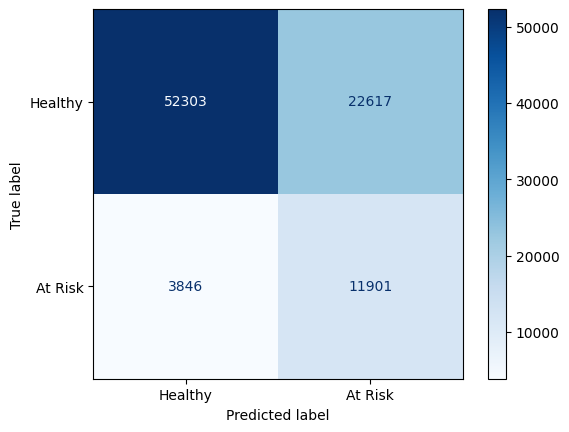

In [27]:
# Evaluate model 2 on the same untouched df1 test set used for models 1 and 3.
y_prob2 = model2.predict(xtest_scaled_df1, verbose=0).ravel()
y_pred2 = (y_prob2 >= 0.5).astype(int)

print(classification_report(
    ytest_df1,
    y_pred2,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm = confusion_matrix(ytest_df1, y_pred2)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.savefig(ASSET_DIR / "confusion_matrix_model2_balanced.png", dpi=300, bbox_inches="tight")
plt.show()

# SMOTE

              precision    recall  f1-score   support

     Healthy       0.93      0.72      0.81     74920
     At Risk       0.36      0.72      0.48     15747

    accuracy                           0.72     90667
   macro avg       0.64      0.72      0.64     90667
weighted avg       0.83      0.72      0.75     90667

[[54245 20675]
 [ 4367 11380]]


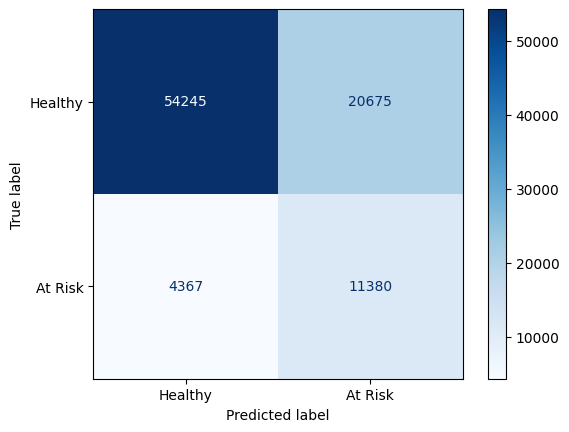

In [28]:
# Evaluate model 3 (SMOTE) on the same untouched df1 test set.
y_prob3 = model3.predict(xtest_scaled_df1, verbose=0).ravel()
y_pred3 = (y_prob3 >= 0.5).astype(int)

print(classification_report(
    ytest_df1,
    y_pred3,
    target_names=["Healthy", "At Risk"],
    zero_division=0
))

cm = confusion_matrix(ytest_df1, y_pred3)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "At Risk"]
).plot(cmap=plt.cm.Blues)

plt.savefig(ASSET_DIR / "confusion_matrix_model3_smote.png", dpi=300, bbox_inches="tight")
plt.show()

# Save Evaluation Metrics to JSON

In [29]:
metrics_dict = {
    "Model 1 (Raw + Class Weights)": classification_report(ytest_df1, y_pred1, target_names=["Healthy", "At Risk"], output_dict=True),
    "Model 2 (Downsampled 50:50)": classification_report(ytest_df1, y_pred2, target_names=["Healthy", "At Risk"], output_dict=True),
    "Model 3 (SMOTE)": classification_report(ytest_df1, y_pred3, target_names=["Healthy", "At Risk"], output_dict=True)
}

# Save to Assets directory
MODEL_DIR.mkdir(parents=True, exist_ok=True)
eval_path = MODEL_DIR / "model_evaluations.json"

with open(eval_path, "w") as f:
    json.dump(metrics_dict, f, indent=4)

print(f"Model evaluations successfully saved to {eval_path}")

Model evaluations successfully saved to D:\ANN-health-risk-prediction-project\Models\model_evaluations.json


# Save All Three Models and Preprocessor

In [30]:
# Save Keras models
model1.save(MODEL_DIR / "model1_raw_weights.h5")
model2.save(MODEL_DIR / "model2_downsampled.h5")
model3.save(MODEL_DIR / "model3_smote.h5")

# Save preprocessor
joblib.dump(preprocessor, MODEL_DIR / "scaler_preprocessor.pkl")
print("All models and preprocessor saved successfully!")

All models and preprocessor saved successfully!


In [31]:
import joblib
preprocessor = joblib.load(MODEL_DIR / "scaler_preprocessor.pkl")
print(preprocessor)
print(preprocessor.transformers_)

ColumnTransformer(remainder='passthrough',
                  transformers=[('scaler', StandardScaler(),
                                 ['BMI', 'MentHlth', 'PhysHlth', 'GenHlth',
                                  'Age', 'Education', 'Income'])])
[('scaler', StandardScaler(), ['BMI', 'MentHlth', 'PhysHlth', 'GenHlth', 'Age', 'Education', 'Income']), ('remainder', FunctionTransformer(accept_sparse=True, check_inverse=False,
                    feature_names_out='one-to-one'), ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'])]
